# TP WordCount - Python et Hadoop
Je compare trois méthodes de comptage de mots sur plusieurs tailles de fichiers.

## 1- Fichiers de test
Je crée un fichier de 100 lignes, puis je le répète pour obtenir quatre tailles.

In [1]:
from pathlib import Path
import random

frequences = {
    "chat": 24, "chien": 11, "arbre": 7, "fleur": 7,
    "maison": 5, "soleil": 5, "montagne": 5,
    "livre": 4, "ciel": 4, "mer": 3, "lune": 3,
    "route": 3, "oiseau": 2, "jardin": 1, "voiture": 1
}
mots = [mot for mot, nb in frequences.items() for _ in range(nb)]
random.seed(42)
random.shuffle(mots)

random.seed(42)
base = mots.copy()
while len(base) < 100:
    base.append(random.choice(mots))
random.shuffle(base)

for m in [1, 10, 100, 1000]:
    fichier = Path(f"mots_{100*m}.txt")
    fichier.write_text(("\n".join(base) + "\n") * m, encoding="utf-8")
    print(f"{fichier.name} : {100*m} lignes")

mots_100.txt : 100 lignes
mots_1000.txt : 1000 lignes
mots_10000.txt : 10000 lignes
mots_100000.txt : 100000 lignes


## 2- Python simple et pseudo-MapReduce
Les deux versions comptent les mêmes mots, mais la deuxième utilise Map, Shuffle et Reduce.

In [2]:
from collections import defaultdict

def compter_simple(fichier):
    mots = Path(fichier).read_text(encoding="utf-8").split()
    compteur = {}
    for mot in mots:
        compteur[mot] = compteur.get(mot, 0) + 1
    return compteur

def compter_pseudo(fichier):
    mots = Path(fichier).read_text(encoding="utf-8").split()
    mapped = [(mot, 1) for mot in mots]       # Map
    grouped = defaultdict(list)
    for mot, valeur in mapped:
        grouped[mot].append(valeur)            # Shuffle
    return {mot: sum(v) for mot, v in grouped.items()}  # Reduce

for n in [100, 1000, 10000, 100000]:
    a = compter_simple(f"mots_{n}.txt")
    b = compter_pseudo(f"mots_{n}.txt")
    assert a == b and sum(a.values()) == n
    print(f"{n} lignes : mêmes résultats ({len(a)} mots différents)")

100 lignes : mêmes résultats (15 mots différents)
1000 lignes : mêmes résultats (15 mots différents)
10000 lignes : mêmes résultats (15 mots différents)
100000 lignes : mêmes résultats (15 mots différents)


## 3- Hadoop
J’ai exécuté WordCount sur HDFS avec YARN sous Ubuntu ; les résultats ont aussi été vérifiés pour les quatre tailles.

Commande utilisée pour un fichier, par exemple :

```bash
hadoop jar "$HADOOP_HOME/share/hadoop/mapreduce/hadoop-mapreduce-examples-3.4.3.jar" \
  wordcount /user/$USER/wordcount/comparaison/input/mots_100.txt \
  /user/$USER/wordcount/comparaison/output_100
```

## 4- Temps mesurés
Je reprends les temps obtenus sous Ubuntu pour les trois méthodes.

In [3]:
import csv

csv_fichier = Path("resultats_comparaison.csv")
if csv_fichier.exists():
    with csv_fichier.open(encoding="utf-8", newline="") as f:
        resultats = list(csv.DictReader(f))
    print("Résultats lus depuis resultats_comparaison.csv")
else:
    # Temps réellement mesurés pendant le TP sous Ubuntu. ( Voir Rapport.pdf)
    resultats = [
        {"lignes": 100, "python_s": 0.0357, "pseudo_mapreduce_s": 0.0368, "hadoop_s": 27.2230},
        {"lignes": 1000, "python_s": 0.0195, "pseudo_mapreduce_s": 0.0179, "hadoop_s": 25.4824},
        {"lignes": 10000, "python_s": 0.0235, "pseudo_mapreduce_s": 0.0350, "hadoop_s": 24.8101},
        {"lignes": 100000, "python_s": 0.0482, "pseudo_mapreduce_s": 0.1311, "hadoop_s": 23.4086},
    ]
    print("Résultats déjà mesurés sous Ubuntu")

print(f"{'Lignes':>9} | {'Python (s)':>10} | {'Pseudo (s)':>10} | {'Hadoop (s)':>10}")
for r in resultats:
    print(f"{int(r['lignes']):>9} | {float(r['python_s']):>10.4f} | {float(r['pseudo_mapreduce_s']):>10.4f} | {float(r['hadoop_s']):>10.4f}")

Résultats déjà mesurés sous Ubuntu
   Lignes | Python (s) | Pseudo (s) | Hadoop (s)
      100 |     0.0357 |     0.0368 |    27.2230
     1000 |     0.0195 |     0.0179 |    25.4824
    10000 |     0.0235 |     0.0350 |    24.8101
   100000 |     0.0482 |     0.1311 |    23.4086


## 5- Graphiques
Le premier graphique compare les trois méthodes, et le deuxième montre mieux les différences entre les deux versions Python.

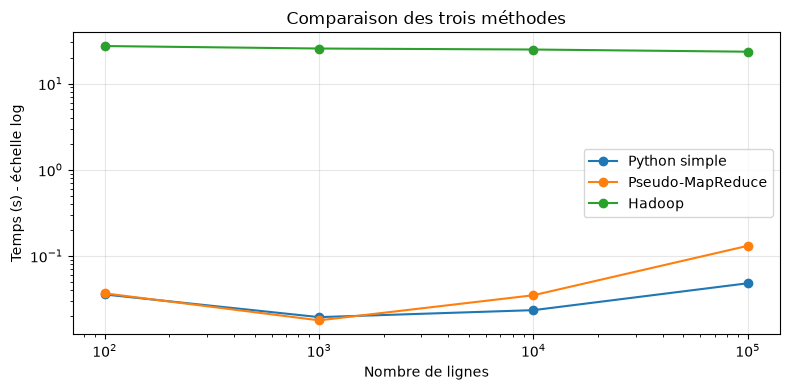

In [6]:
import matplotlib.pyplot as plt

tailles = [int(r["lignes"]) for r in resultats]
plt.figure(figsize=(8, 4))
for colonne, nom in [("python_s", "Python simple"),
                     ("pseudo_mapreduce_s", "Pseudo-MapReduce"),
                     ("hadoop_s", "Hadoop")]:
    plt.plot(tailles, [float(r[colonne]) for r in resultats], marker="o", label=nom)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Nombre de lignes")
plt.ylabel("Temps (s) - échelle log")
plt.title("Comparaison des trois méthodes")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

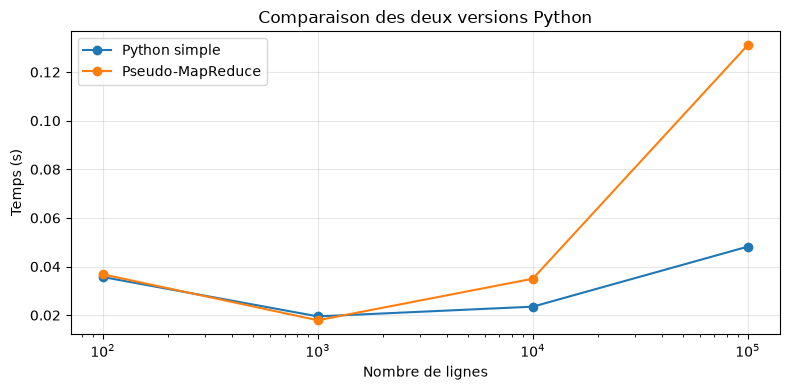

In [7]:
plt.figure(figsize=(8, 4))
for colonne, nom in [("python_s", "Python simple"),
                     ("pseudo_mapreduce_s", "Pseudo-MapReduce")]:
    plt.plot(tailles, [float(r[colonne]) for r in resultats], marker="o", label=nom)
plt.xscale("log")
plt.xlabel("Nombre de lignes")
plt.ylabel("Temps (s)")
plt.title("Comparaison des deux versions Python")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

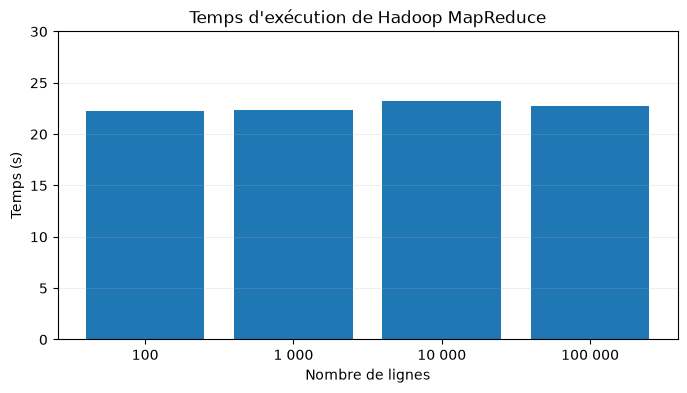

In [8]:
import matplotlib.pyplot as plt

lignes = [100, 1000, 10000, 100000]
temps = [22.2939, 22.3677, 23.2699, 22.7530]

plt.figure(figsize=(8, 4))
plt.bar(range(4), temps)

plt.xticks(range(4), ["100", "1 000", "10 000", "100 000"])
plt.xlabel("Nombre de lignes")
plt.ylabel("Temps (s)")
plt.title("Temps d'exécution de Hadoop MapReduce")
plt.ylim(0, 30)
plt.grid(axis="y", alpha=0.2)

plt.show()

## 6- Conclusion
Les trois méthodes donnent les mêmes comptages. Pour ces fichiers, Python est plus rapide, car Hadoop met du temps à lancer les tâches. Sur de gros volumes et plusieurs machines, Hadoop peut devenir plus intéressant.